# STLab03 · EduParking
Lê Phan Thanh Thiên Định · 23110074

Chạy từ trên xuống. Mỗi lần chạy tạo lại v1 từ đề trước khi sinh hai bộ báo cáo.

In [1]:
import importlib.util, os, subprocess, sys, json, csv, tempfile, shutil
from pathlib import Path
packages = {"pytest":"pytest","pytest_cov":"pytest-cov","pytest_html":"pytest-html","openpyxl":"openpyxl","matplotlib":"matplotlib","pandas":"pandas"}
missing = [dist for mod, dist in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import pandas as pd
from IPython.display import display, Image
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
TESTS = ["test_functions.py", "test_parking.py"]
def pytest_run(*args):
    return subprocess.run([sys.executable, "-m", "pytest", "-p", "no:cacheprovider", *args], text=True, capture_output=True)


## 1. Requirement và dữ liệu kiểm thử
Trần phí áp cho một lượt gửi. Mã A và B là hai biển hợp lệ khác nhau. Các mốc thời gian tính từ 08:00 ngày 01/11/2026.

In [2]:
%%writefile requirements.json
{
  "REQ-01": "Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",
  "REQ-02": "Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",
  "REQ-03": "MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",
  "REQ-04": "CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",
  "REQ-05": "Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY",
  "REQ-06": "Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",
  "REQ-07": "Check-in thành công: ghi nhận xe, số xe trong bãi tăng 1",
  "REQ-08": "Bãi đầy báo LOT_FULL; dữ liệu không đổi",
  "REQ-09": "Xe đang ở trong bãi check-in lại báo ALREADY_INSIDE; số xe không đổi",
  "REQ-10": "Check-out: trả về phí, số xe giảm 1, xóa xe khỏi bãi, doanh thu CỘNG DỒN",
  "REQ-11": "Check-out xe không có trong bãi báo NOT_INSIDE",
  "REQ-12": "Mất vé: cộng phụ thu 50.000đ vào phí VÀ vào doanh thu"
}

Overwriting requirements.json


In [3]:
%%writefile test_data.csv
REQ,Loại,Tiền điều kiện,Input,Expected,Căn cứ,Assertion,Test
REQ-01,positive,Hàm thuần,{'plate': '59A-12345'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_positive_plate_format[case1]
REQ-01,negative,Hàm thuần,{'plate': ''},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_negative_plate_format[case1]
REQ-01,negative,Hàm thuần,{'plate': '59a-12345'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_negative_plate_format[case2]
REQ-01,negative,Hàm thuần,{'plate': '59A12345'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_negative_plate_format[case3]
REQ-01,negative,Hàm thuần,{'plate': '59A-1234'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_negative_plate_format[case4]
REQ-01,negative,Hàm thuần,{'plate': '59A-123456'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_negative_plate_format[case5]
REQ-01,edge,Hàm thuần,{'plate': '00A-00000'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_edge_plate_format[case1]
REQ-01,edge,Hàm thuần,{'plate': '99Z-99999'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, gạch nối, 5 số), ví dụ 59A-12345",boolean,test_edge_plate_format[case2]
REQ-02,positive,Hàm thuần,{'seconds': 1800},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_positive_duration[case1]
REQ-02,edge,Hàm thuần,{'seconds': 0},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case1]
REQ-02,edge,Hàm thuần,{'seconds': 1},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case2]
REQ-02,edge,Hàm thuần,{'seconds': 3599},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case3]
REQ-02,edge,Hàm thuần,{'seconds': 3600},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case4]
REQ-02,edge,Hàm thuần,{'seconds': 3601},2,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case5]
REQ-02,edge,Hàm thuần,{'seconds': 7200},2,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",equality,test_edge_duration[case6]
REQ-02,negative,Ra sớm 1 giây,Ra sớm 1 giây,INVALID_TIME,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ; đúng 60 phút tính 1 giờ; giờ ra trước giờ vào báo INVALID_TIME",raises,test_negative_reversed_time
REQ-03,positive,MOTORBIKE,{'hours': 2},5000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_positive_fee[case1]
REQ-03,edge,MOTORBIKE,{'hours': 1},5000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_edge_fee[case1]
REQ-03,edge,MOTORBIKE,{'hours': 4},5000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_edge_fee[case2]
REQ-03,edge,MOTORBIKE,{'hours': 5},7000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_edge_fee[case3]
REQ-03,edge,MOTORBIKE,{'hours': 16},29000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_edge_fee[case4]
REQ-03,edge,MOTORBIKE,{'hours': 17},30000,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",equality,test_edge_fee[case5]
REQ-03,negative,MOTORBIKE,{'hours': 0},INVALID_HOURS,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",raises,test_negative_hours[case1]
REQ-03,negative,MOTORBIKE,{'hours': -1},INVALID_HOURS,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/giờ, tối đa 30.000đ; số giờ < 1 báo INVALID_HOURS",raises,test_negative_hours[case2]
REQ-04,positive,CAR,{'hours': 5},50000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_positive_fee[case1]
REQ-04,edge,CAR,{'hours': 1},20000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case1]
REQ-04,edge,CAR,{'hours': 2},20000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case2]
REQ-04,edge,CAR,{'hours': 3},30000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case3]
REQ-04,edge,CAR,{'hours': 19},190000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case4]
REQ-04,edge,CAR,{'hours': 20},200000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case5]
REQ-04,edge,CAR,{'hours': 21},200000,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",equality,test_edge_fee[case6]
REQ-04,negative,"TRUCK, 1 giờ","TRUCK, 1 giờ",INVALID_VEHICLE,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",raises,test_negative_unknown_fee
REQ-04,negative,"Bãi trống, A, TRUCK","Bãi trống, A, TRUCK","INVALID_VEHICLE, giữ state","CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, tối đa 200.000đ; loại xe khác báo INVALID_VEHICLE (cả khi check-in)",raises + state,test_negative_unknown_entry
REQ-05,positive,Hàm thuần,"{'occupied': 1, 'capacity': 3}",33.333333333,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY,approx,test_positive_occupancy[case1]
REQ-05,edge,Hàm thuần,"{'occupied': 0, 'capacity': 10}",0,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY,approx,test_edge_occupancy[case1]
REQ-05,edge,Hàm thuần,"{'occupied': 10, 'capacity': 10}",100,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY,approx,test_edge_occupancy[case2]
REQ-05,negative,Hàm thuần,{'capacity': 0},INVALID_CAPACITY,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY,raises,test_negative_capacity[case1]
REQ-05,negative,Hàm thuần,{'capacity': -1},INVALID_CAPACITY,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức chứa ≤ 0 báo INVALID_CAPACITY,raises,test_negative_capacity[case2]
REQ-06,positive,"A hợp lệ, ngoài blacklist",{'debt': 0},True,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_positive_debt[case1]
REQ-06,edge,"A hợp lệ, ngoài blacklist",{'debt': 99999},True,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_edge_debt[case1]
REQ-06,edge,"A hợp lệ, ngoài blacklist",{'debt': 100000},False,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_edge_debt[case2]
REQ-06,edge,"A hợp lệ, ngoài blacklist",{'debt': 100001},False,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_edge_debt[case3]
REQ-06,negative,bad_plate,bad_plate,NOT_ALLOWED; state giữ nguyên,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",raises + state,test_negative_bad_plate
REQ-06,negative,bad_plate,bad_plate,False,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_negative_can_enter_bad_plate
REQ-06,negative,blacklist,blacklist,NOT_ALLOWED; state giữ nguyên,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",raises + state,test_negative_blacklist
REQ-06,negative,blacklist,blacklist,False,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",boolean,test_negative_can_enter_blacklist
REQ-06,negative,debt_limit,debt_limit,NOT_ALLOWED; state giữ nguyên,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",raises + state,test_negative_debt_limit
REQ-06,negative,Biển sai và TRUCK,Biển sai và TRUCK,NOT_ALLOWED; state giữ nguyên,"Được vào khi: biển số hợp lệ, không trong danh sách đen, nợ DƯỚI 100.000đ; ngược lại check-in báo NOT_ALLOWED",raises + state,test_negative_eligibility_before_vehicle
REQ-07,positive,"Bãi trống, nhận A/CAR","Bãi trống, nhận A/CAR","1 xe, A=(CAR, START)","Check-in thành công: ghi nhận xe, số xe trong bãi tăng 1",equality,test_positive_first_entry
REQ-07,edge,"B đã vào, nhận A/CAR","B đã vào, nhận A/CAR","2 xe, A=(CAR, START)","Check-in thành công: ghi nhận xe, số xe trong bãi tăng 1",equality,test_edge_last_space
REQ-07,positive,"Bãi trống, nhận A/CAR","Bãi trống, nhận A/CAR","1 xe, A=(CAR, START)","Check-in thành công: ghi nhận xe, số xe trong bãi tăng 1",equality,test_positive_recorded_vehicle
REQ-08,negative,"Bãi 2/2, biển mới","Bãi 2/2, biển mới",LOT_FULL; state giữ nguyên,Bãi đầy báo LOT_FULL; dữ liệu không đổi,raises + state,test_negative_full
REQ-08,edge,"Bãi 2/2, A đã ở trong","Bãi 2/2, A đã ở trong",LOT_FULL; state giữ nguyên,Bãi đầy báo LOT_FULL; dữ liệu không đổi,raises + state,test_edge_full_before_duplicate
REQ-08,negative,"Bãi đầy, trùng biển, TRUCK","Bãi đầy, trùng biển, TRUCK",INVALID_VEHICLE; state giữ nguyên,Bãi đầy báo LOT_FULL; dữ liệu không đổi,raises + state,test_negative_vehicle_before_full
REQ-09,negative,"A đã vào, còn 1 chỗ","A đã vào, còn 1 chỗ",ALREADY_INSIDE,Xe đang ở trong bãi check-in lại báo ALREADY_INSIDE; số xe không đổi,raises,test_negative_duplicate_error
REQ-09,edge,"A đã vào, nhập lại với loại/giờ khác","A đã vào, nhập lại với loại/giờ khác",ALREADY_INSIDE; state giữ nguyên,Xe đang ở trong bãi check-in lại báo ALREADY_INSIDE; số xe không đổi,raises + state,test_edge_duplicate_preserves_state
REQ-10,positive,"Chỉ A, ra sau 30 phút, thu cũ 7.000","Chỉ A, ra sau 30 phút, thu cũ 7.000","Phí 20.000, thu 27.000, xóa riêng A","Check-out: trả về phí, số xe giảm 1, xóa xe khỏi bãi, doanh thu CỘNG DỒN",equality,test_positive_removes_car
REQ-10,positive,"A và B, ra sau 30 phút, thu cũ 7.000","A và B, ra sau 30 phút, thu cũ 7.000","Phí 20.000, thu 27.000, xóa riêng A","Check-out: trả về phí, số xe giảm 1, xóa xe khỏi bãi, doanh thu CỘNG DỒN",equality,test_positive_keeps_other
REQ-10,negative,A ra sớm 1 giây,A ra sớm 1 giây,INVALID_TIME; state giữ nguyên,"Check-out: trả về phí, số xe giảm 1, xóa xe khỏi bãi, doanh thu CỘNG DỒN",raises + state,test_negative_clock_reversed
REQ-11,negative,"Bãi trống, A vắng","Bãi trống, A vắng",NOT_INSIDE; state giữ nguyên,Check-out xe không có trong bãi báo NOT_INSIDE,raises + state,test_negative_absent
REQ-11,edge,"B đã vào, A vắng","B đã vào, A vắng",NOT_INSIDE; state giữ nguyên,Check-out xe không có trong bãi báo NOT_INSIDE,raises + state,test_edge_other_car
REQ-12,positive,"CAR A, thu cũ 7.000; expected là phí và phần tăng doanh thu","{'minutes': 30, 'lost': False}",20000,Mất vé: cộng phụ thu 50.000đ vào phí VÀ vào doanh thu,equality,test_positive_ticket[case1]
REQ-12,positive,"CAR A, thu cũ 7.000; expected là phí và phần tăng doanh thu","{'minutes': 30, 'lost': True}",70000,Mất vé: cộng phụ thu 50.000đ vào phí VÀ vào doanh thu,equality,test_positive_ticket[case2]
REQ-12,edge,"CAR A, thu cũ 7.000; expected là phí và phần tăng doanh thu","{'minutes': 1300, 'lost': True}",250000,Mất vé: cộng phụ thu 50.000đ vào phí VÀ vào doanh thu,equality,test_edge_ticket_above_cap[case1]


Overwriting test_data.csv


In [4]:
REQUIREMENTS = json.loads(Path("requirements.json").read_text())
data = pd.read_csv("test_data.csv")
with pd.option_context("display.max_rows", None): display(data)

,REQ,Loại,Tiền điều kiện,Input,Expected,Căn cứ,Assertion,Test
0,REQ-01,positive,Hàm thuần,{'plate': '59A-12345'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_positive_plate_format[case1]
1,REQ-01,negative,Hàm thuần,{'plate': ''},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_negative_plate_format[case1]
2,REQ-01,negative,Hàm thuần,{'plate': '59a-12345'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_negative_plate_format[case2]
3,REQ-01,negative,Hàm thuần,{'plate': '59A12345'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_negative_plate_format[case3]
4,REQ-01,negative,Hàm thuần,{'plate': '59A-1234'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_negative_plate_format[case4]
5,REQ-01,negative,Hàm thuần,{'plate': '59A-123456'},False,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_negative_plate_format[case5]
6,REQ-01,edge,Hàm thuần,{'plate': '00A-00000'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_edge_plate_format[case1]
7,REQ-01,edge,Hàm thuần,{'plate': '99Z-99999'},True,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",boolean,test_edge_plate_format[case2]
8,REQ-02,positive,Hàm thuần,{'seconds': 1800},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ...",equality,test_positive_duration[case1]
9,REQ-02,edge,Hàm thuần,{'seconds': 0},1,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ...",equality,test_edge_duration[case1]


## 2. Ứng dụng v1 và unit test

In [5]:
%%writefile parking_app.py
"""EduParking v1: bãi giữ xe chạy trong bộ nhớ, dùng cho bài tập STLab03."""
import re
from datetime import datetime

# loại xe: (giá gói đầu, số giờ gói đầu, giá mỗi giờ thêm, mức trần)
PRICE = {"MOTORBIKE": (5_000, 4, 2_000, 30_000), "CAR": (20_000, 2, 10_000, 200_000)}
DEBT_LIMIT = 100_000
LOST_TICKET = 50_000


# ---------- PHẦN A: hàm thuần ----------
def is_valid_plate(plate):
    return bool(re.fullmatch(r"[0-9]{2}[A-Z]-[0-9]{5}", plate))


def parked_hours(time_in, time_out):
    if time_out < time_in:
        raise ValueError("INVALID_TIME")
    minutes = int((time_out - time_in).total_seconds() // 60)
    return minutes // 60 + 1


def parking_fee(vehicle, hours):
    if vehicle not in PRICE:
        raise ValueError("INVALID_VEHICLE")
    if hours < 1:
        raise ValueError("INVALID_HOURS")
    base, base_hours, extra, cap = PRICE[vehicle]
    fee = base + max(0, hours - base_hours) * extra
    return min(fee, cap)


def occupancy_rate(occupied, capacity):
    if capacity <= 0:
        raise ValueError("INVALID_CAPACITY")
    return occupied / capacity * 100


# ---------- PHẦN B: lớp có state ----------
class ParkingLot:
    def __init__(self, capacity):
        self.capacity = capacity
        self.occupied = 0
        self.inside = {}            # biển số -> (loại xe, giờ vào)
        self.debts = {}             # biển số -> số tiền nợ
        self.blacklist = set()
        self.revenue = 0

    def can_enter(self, plate):
        return (is_valid_plate(plate)
                and plate not in self.blacklist
                and self.debts.get(plate, 0) <= DEBT_LIMIT)

    def check_in(self, plate, vehicle, time_in):
        if not self.can_enter(plate):
            raise ValueError("NOT_ALLOWED")
        if vehicle not in PRICE:
            raise ValueError("INVALID_VEHICLE")
        if self.occupied >= self.capacity:
            raise ValueError("LOT_FULL")
        self.occupied += 1
        if plate in self.inside:
            raise ValueError("ALREADY_INSIDE")
        self.inside[plate] = (vehicle, time_in)

    def check_out(self, plate, time_out, lost_ticket=False):
        if plate not in self.inside:
            raise ValueError("NOT_INSIDE")
        vehicle, time_in = self.inside[plate]
        fee = parking_fee(vehicle, parked_hours(time_in, time_out))
        self.revenue += fee
        if lost_ticket:
            fee += LOST_TICKET
        del self.inside[plate]
        self.occupied -= 1
        return fee


Overwriting parking_app.py


In [6]:
%%writefile test_functions.py
from datetime import datetime, timedelta

import pytest

from parking_app import ParkingLot, is_valid_plate, parked_hours, parking_fee, occupancy_rate

START = datetime(2026, 11, 1, 8)
A = "59A-12345"
B = "59B-12345"


def snapshot(lot):
    return (lot.occupied, lot.inside.copy(), lot.debts.copy(), lot.blacklist.copy(), lot.revenue)


class LotCase:
    def setup_method(self):
        self.lot = ParkingLot(2)


class TestReq01:
    @pytest.mark.parametrize('plate, expected', [('59A-12345', True)], ids=['case1'])
    def test_positive_plate_format(self, plate, expected):
        assert is_valid_plate(plate) is expected

    @pytest.mark.parametrize('plate, expected', [('', False), ('59a-12345', False), ('59A12345', False), ('59A-1234', False), ('59A-123456', False)], ids=['case1', 'case2', 'case3', 'case4', 'case5'])
    def test_negative_plate_format(self, plate, expected):
        assert is_valid_plate(plate) is expected

    @pytest.mark.parametrize('plate, expected', [('00A-00000', True), ('99Z-99999', True)], ids=['case1', 'case2'])
    def test_edge_plate_format(self, plate, expected):
        assert is_valid_plate(plate) is expected

class TestReq02:
    @pytest.mark.parametrize('seconds, expected', [(1800, 1)], ids=['case1'])
    def test_positive_duration(self, seconds, expected):
        end = START + timedelta(seconds=seconds)
        assert parked_hours(START, end) == expected

    @pytest.mark.parametrize('seconds, expected', [(0, 1), (1, 1), (3599, 1), (3600, 1), (3601, 2), (7200, 2)], ids=['case1', 'case2', 'case3', 'case4', 'case5', 'case6'])
    def test_edge_duration(self, seconds, expected):
        end = START + timedelta(seconds=seconds)
        assert parked_hours(START, end) == expected

    def test_negative_reversed_time(self):
        with pytest.raises(ValueError, match=r"^INVALID_TIME$"):
            parked_hours(START, START - timedelta(seconds=1))

class TestReq03:
    @pytest.mark.parametrize('hours, expected', [(2, 5000)], ids=['case1'])
    def test_positive_fee(self, hours, expected):
        assert parking_fee("MOTORBIKE", hours) == expected

    @pytest.mark.parametrize('hours, expected', [(1, 5000), (4, 5000), (5, 7000), (16, 29000), (17, 30000)], ids=['case1', 'case2', 'case3', 'case4', 'case5'])
    def test_edge_fee(self, hours, expected):
        assert parking_fee("MOTORBIKE", hours) == expected

    @pytest.mark.parametrize('hours', [0, -1], ids=['case1', 'case2'])
    def test_negative_hours(self, hours):
        with pytest.raises(ValueError, match=r"^INVALID_HOURS$"):
            parking_fee("MOTORBIKE", hours)

class TestReq04:
    @pytest.mark.parametrize('hours, expected', [(5, 50000)], ids=['case1'])
    def test_positive_fee(self, hours, expected):
        assert parking_fee("CAR", hours) == expected

    @pytest.mark.parametrize('hours, expected', [(1, 20000), (2, 20000), (3, 30000), (19, 190000), (20, 200000), (21, 200000)], ids=['case1', 'case2', 'case3', 'case4', 'case5', 'case6'])
    def test_edge_fee(self, hours, expected):
        assert parking_fee("CAR", hours) == expected

    def test_negative_unknown_fee(self):
        with pytest.raises(ValueError, match=r"^INVALID_VEHICLE$"):
            parking_fee("TRUCK", 1)


class TestReq04Entry(LotCase):
    def test_negative_unknown_entry(self):
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^INVALID_VEHICLE$"):
            self.lot.check_in(A, "TRUCK", START)
        assert snapshot(self.lot) == before

class TestReq05:
    @pytest.mark.parametrize('occupied, capacity, expected', [(1, 3, 33.333333333)], ids=['case1'])
    def test_positive_occupancy(self, occupied, capacity, expected):
        assert occupancy_rate(occupied, capacity) == pytest.approx(expected)

    @pytest.mark.parametrize('occupied, capacity, expected', [(0, 10, 0), (10, 10, 100)], ids=['case1', 'case2'])
    def test_edge_occupancy(self, occupied, capacity, expected):
        assert occupancy_rate(occupied, capacity) == pytest.approx(expected)

    @pytest.mark.parametrize('capacity', [0, -1], ids=['case1', 'case2'])
    def test_negative_capacity(self, capacity):
        with pytest.raises(ValueError, match=r"^INVALID_CAPACITY$"):
            occupancy_rate(0, capacity)



Overwriting test_functions.py


In [7]:
%%writefile test_parking.py
from datetime import datetime, timedelta

import pytest

from parking_app import ParkingLot, is_valid_plate, parked_hours, parking_fee, occupancy_rate

START = datetime(2026, 11, 1, 8)
A = "59A-12345"
B = "59B-12345"


def snapshot(lot):
    return (lot.occupied, lot.inside.copy(), lot.debts.copy(), lot.blacklist.copy(), lot.revenue)


class LotCase:
    def setup_method(self):
        self.lot = ParkingLot(2)


class TestReq06(LotCase):
    @pytest.mark.parametrize('debt, expected', [(0, True)], ids=['case1'])
    def test_positive_debt(self, debt, expected):
        self.lot.debts[A] = debt
        assert self.lot.can_enter(A) is expected

    @pytest.mark.parametrize('debt, expected', [(99999, True), (100000, False), (100001, False)], ids=['case1', 'case2', 'case3'])
    def test_edge_debt(self, debt, expected):
        self.lot.debts[A] = debt
        assert self.lot.can_enter(A) is expected

    def test_negative_bad_plate(self):
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_ALLOWED$"):
            self.lot.check_in("bad", "CAR", START)
        assert snapshot(self.lot) == before

    def test_negative_can_enter_bad_plate(self):
        assert self.lot.can_enter("bad") is False

    def test_negative_blacklist(self):
        self.lot.blacklist.add(A)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_ALLOWED$"):
            self.lot.check_in(A, "CAR", START)
        assert snapshot(self.lot) == before

    def test_negative_can_enter_blacklist(self):
        self.lot.blacklist.add(A)
        assert self.lot.can_enter(A) is False

    def test_negative_debt_limit(self):
        self.lot.debts[A] = 100000
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_ALLOWED$"):
            self.lot.check_in(A, "CAR", START)
        assert snapshot(self.lot) == before

    def test_negative_eligibility_before_vehicle(self):
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_ALLOWED$"):
            self.lot.check_in("bad", "TRUCK", START)
        assert snapshot(self.lot) == before

class TestReq07(LotCase):
    def test_positive_first_entry(self):
        self.lot.check_in(A, "CAR", START)
        assert self.lot.occupied == 1
        assert self.lot.inside[A] == ("CAR", START)

    def test_edge_last_space(self):
        self.lot.check_in(B, "MOTORBIKE", START)
        self.lot.check_in(A, "CAR", START)
        assert self.lot.occupied == 2
        assert self.lot.inside[A] == ("CAR", START)

    def test_positive_recorded_vehicle(self):
        self.lot.check_in(A, "CAR", START)
        assert self.lot.occupied == 1
        assert self.lot.inside[A] == ("CAR", START)

class TestReq08(LotCase):
    def test_negative_full(self):
        self.lot.check_in(A, "CAR", START)
        self.lot.check_in(B, "MOTORBIKE", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^LOT_FULL$"):
            self.lot.check_in("59C-12345", "CAR", START)
        assert snapshot(self.lot) == before

    def test_edge_full_before_duplicate(self):
        self.lot.check_in(A, "CAR", START)
        self.lot.check_in(B, "MOTORBIKE", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^LOT_FULL$"):
            self.lot.check_in(A, "CAR", START)
        assert snapshot(self.lot) == before

    def test_negative_vehicle_before_full(self):
        self.lot.check_in(A, "CAR", START)
        self.lot.check_in(B, "MOTORBIKE", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^INVALID_VEHICLE$"):
            self.lot.check_in(A, "TRUCK", START)
        assert snapshot(self.lot) == before

class TestReq09(LotCase):
    def test_negative_duplicate_error(self):
        self.lot.check_in(A, "CAR", START)
        with pytest.raises(ValueError, match=r"^ALREADY_INSIDE$"):
            self.lot.check_in(A, "CAR", START)

    def test_edge_duplicate_preserves_state(self):
        self.lot.check_in(A, "CAR", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^ALREADY_INSIDE$"):
            self.lot.check_in(A, "MOTORBIKE", START + timedelta(minutes=2))
        assert snapshot(self.lot) == before

class TestReq10(LotCase):
    def test_positive_removes_car(self):
        self.lot.check_in(A, "CAR", START)
        self.lot.revenue = 7000
        fee = self.lot.check_out(A, START + timedelta(minutes=30))
        assert fee == 20000
        assert self.lot.revenue == 27000
        assert self.lot.inside == {}
        assert self.lot.occupied == 0

    def test_positive_keeps_other(self):
        self.lot.check_in(B, "MOTORBIKE", START)
        self.lot.check_in(A, "CAR", START)
        self.lot.revenue = 7000
        fee = self.lot.check_out(A, START + timedelta(minutes=30))
        assert fee == 20000
        assert self.lot.revenue == 27000
        assert self.lot.inside == {B: ("MOTORBIKE", START)}
        assert self.lot.occupied == 1

    def test_negative_clock_reversed(self):
        self.lot.check_in(A, "CAR", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^INVALID_TIME$"):
            self.lot.check_out(A, START - timedelta(seconds=1))
        assert snapshot(self.lot) == before

class TestReq11(LotCase):
    def test_negative_absent(self):
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_INSIDE$"):
            self.lot.check_out(A, START)
        assert snapshot(self.lot) == before

    def test_edge_other_car(self):
        self.lot.check_in(B, "MOTORBIKE", START)
        before = snapshot(self.lot)
        with pytest.raises(ValueError, match=r"^NOT_INSIDE$"):
            self.lot.check_out(A, START)
        assert snapshot(self.lot) == before

class TestReq12(LotCase):
    @pytest.mark.parametrize('minutes, lost, expected', [(30, False, 20000), (30, True, 70000)], ids=['case1', 'case2'])
    def test_positive_ticket(self, minutes, lost, expected):
        self.lot.check_in(A, "CAR", START)
        self.lot.revenue = 7000
        fee = self.lot.check_out(A, START + timedelta(minutes=minutes), lost_ticket=lost)
        assert fee == expected
        assert self.lot.revenue == 7000 + expected
        assert self.lot.occupied == 0
        assert self.lot.inside == {}

    @pytest.mark.parametrize('minutes, lost, expected', [(1300, True, 250000)], ids=['case1'])
    def test_edge_ticket_above_cap(self, minutes, lost, expected):
        self.lot.check_in(A, "CAR", START)
        self.lot.revenue = 7000
        fee = self.lot.check_out(A, START + timedelta(minutes=minutes), lost_ticket=lost)
        assert fee == expected
        assert self.lot.revenue == 7000 + expected
        assert self.lot.occupied == 0
        assert self.lot.inside == {}



Overwriting test_parking.py


In [8]:
%%writefile test_report.py
"""Chạy pytest rồi xuất Test Report: JUnit XML, CSV, Excel, HTML và biểu đồ PNG."""
import html
import json
import re
import subprocess
import sys
import xml.etree.ElementTree as ET
from datetime import datetime
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd


def run_pytest(out, module, tests):
    """Bước 1: gọi pytest, sinh kết quả thô (XML), báo cáo HTML và số liệu coverage."""
    cmd = [sys.executable, "-m", "pytest", *tests, "-q", "--tb=line", "-p", "no:cacheprovider",
           f"--junitxml={out / 'junit.xml'}",
           f"--html={out / 'pytest_report.html'}", "--self-contained-html",
           f"--cov={module}", "--cov-branch", f"--cov-report=json:{out / 'coverage.json'}"]
    done = subprocess.run(cmd, capture_output=True, text=True)
    (out / "pytest_log.txt").write_text(done.stdout + done.stderr, encoding="utf-8")
    if done.returncode not in (0, 1):              # 0: pass hết, 1: có fail, khác: lỗi cấu hình
        raise RuntimeError(done.stdout + done.stderr)


def read_results(junit_file):
    """Bước 2: đọc junit.xml. Tên lớp -> REQ, tên hàm -> loại test."""
    rows = []
    for i, case in enumerate(ET.parse(junit_file).iter("testcase"), 1):
        bad = case.find("failure")
        err = case.find("error")
        skip = case.find("skipped")
        status = "FAIL" if bad is not None else "BLOCKED" if err is not None or skip is not None else "PASS"
        node = next((n for n in (bad, err, skip) if n is not None), None)
        cls = case.get("classname", "").split(".")[-1]
        req = re.match(r"TestReq(\d+)", cls)
        kind = re.match(r"test_(positive|negative|edge)_", case.get("name"))
        rows.append({
            "test_id": f"TC-{i:03d}",
            "requirement": f"REQ-{req.group(1)}" if req else "UNMAPPED",
            "type": kind.group(1) if kind else "other",
            "test_name": case.get("name"),
            "status": status,
            "time_s": float(case.get("time", 0)),
            "message": (node.get("message") or "").replace("\n", " ")[:160] if node is not None else "",
        })
    return pd.DataFrame(rows)


def build_report(name, module, tests, requirements, out_dir):
    """Bước 3: tổng hợp và xuất mọi định dạng. Trả về (bảng chi tiết, bảng tổng hợp, coverage)."""
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    run_pytest(out, module, tests)
    df = read_results(out / "junit.xml")
    cov = json.loads((out / "coverage.json").read_text())["totals"]
    line = round(100 * cov["covered_lines"] / cov["num_statements"], 1)
    branch = round(100 * cov["covered_branches"] / cov["num_branches"], 1) if cov["num_branches"] else 100.0
    n = df["status"].value_counts().reindex(["PASS", "FAIL", "BLOCKED"], fill_value=0)
    summary = pd.DataFrame([{
        "executed": len(df), "pass": n["PASS"], "fail": n["FAIL"], "blocked": n["BLOCKED"],
        "pass_rate_%": round(100 * n["PASS"] / len(df), 1),
        "req_covered": f"{df['requirement'].isin(requirements).groupby(df['requirement']).any().sum()}/{len(requirements)}",
        "line_cov_%": line, "branch_cov_%": branch}])
    trace = (df.groupby(["requirement", "status"]).size().unstack(fill_value=0)
               .reindex(columns=["PASS", "FAIL", "BLOCKED"], fill_value=0)
               .reindex(list(requirements), fill_value=0))
    trace.columns.name = None
    trace.insert(0, "description", [requirements[r] for r in trace.index])
    trace["result"] = ["NOT TESTED" if a + b + c == 0 else "PASS" if b + c == 0 else "FAIL"
                       for a, b, c in trace[["PASS", "FAIL", "BLOCKED"]].values]
    trace = trace.reset_index().rename(columns={"index": "requirement"})

    df.to_csv(out / "test_execution.csv", index=False, encoding="utf-8-sig")
    with pd.ExcelWriter(out / "test_report.xlsx", engine="openpyxl") as xls:
        for sheet, data in (("Summary", summary), ("Traceability", trace),
                            ("Execution", df), ("Failures", df[df.status != "PASS"])):
            data.to_excel(xls, index=False, sheet_name=sheet)
            for col in xls.sheets[sheet].columns:
                width = max(len(str(c.value or "")) for c in col)
                xls.sheets[sheet].column_dimensions[col[0].column_letter].width = min(width + 3, 60)
    draw_chart(trace, df, name, out / "chart.png")
    write_html(name, summary, trace, df, out / "dashboard.html")
    print(f"{name}: executed {len(df)} | PASS {n['PASS']} | FAIL {n['FAIL']} | BLOCKED {n['BLOCKED']}"
          f" | line {line}% | branch {branch}%")
    return df, summary, trace


def draw_chart(trace, df, name, file):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
    a.bar(trace.requirement, trace.PASS, color="#16a34a", label="PASS")
    a.bar(trace.requirement, trace.FAIL + trace.BLOCKED, bottom=trace.PASS, color="#dc2626", label="FAIL/BLOCKED")
    a.tick_params(axis="x", rotation=45)
    a.set_ylabel("Test cases")
    a.set_title(name)
    a.legend()
    kinds = df.groupby("type").size()
    bars = b.barh(kinds.index, kinds.values, color="#2F75B5")
    b.bar_label(bars, padding=3)
    b.set_title("Test type")
    b.set_xlim(0, kinds.max() * 1.15)
    fig.tight_layout()
    fig.savefig(file, dpi=130)
    plt.close(fig)


def write_html(name, summary, trace, df, file):
    def cells(row, tag="td"):
        return "".join(f'<{tag} class="{v}">{html.escape(str(v))}</{tag}>' for v in row)

    def table(data):
        body = "".join(f"<tr>{cells(r)}</tr>" for r in data.values)
        return f"<table><tr>{cells(data.columns, 'th')}</tr>{body}</table>"

    cards = "".join(f'<div class="card"><b>{html.escape(str(v))}</b><span>{k}</span></div>'
                    for k, v in summary.iloc[0].items())
    file.write_text(f"""<!DOCTYPE html><html><head><meta charset="utf-8"><title>{name}</title><style>
body{{font:14px Arial;margin:28px;color:#14233c}}h1{{color:#17385f;margin:0}}table{{border-collapse:collapse;width:100%;margin:8px 0 20px}}
td,th{{border:1px solid #cbd5e1;padding:6px 8px;text-align:left}}th{{background:#16385e;color:#fff}}
.card{{display:inline-block;background:#edf3f9;border-radius:10px;padding:10px 16px;margin:12px 8px 8px 0}}
.card b{{display:block;font-size:22px}}.PASS{{color:#15803d;font-weight:700}}.FAIL,.BLOCKED{{color:#b91c1c;font-weight:700}}
th.PASS,th.FAIL,th.BLOCKED{{color:#fff}}</style></head><body><h1>{name}</h1>
<div>Generated: {datetime.now():%d/%m/%Y %H:%M}</div>{cards}<h2>Requirement traceability</h2>{table(trace)}
<img src="chart.png" style="max-width:900px"><h2>Execution details</h2>{table(df)}</body></html>""", encoding="utf-8")


Overwriting test_report.py


## 3. Thu thập test và chạy report v1

Matplotlib is building the font cache; this may take a moment.


test_functions.py::TestReq01::test_positive_plate_format[case1]
test_functions.py::TestReq01::test_negative_plate_format[case1]
test_functions.py::TestReq01::test_negative_plate_format[case2]
test_functions.py::TestReq01::test_negative_plate_format[case3]
test_functions.py::TestReq01::test_negative_plate_format[case4]
test_functions.py::TestReq01::test_negative_plate_format[case5]
test_functions.py::TestReq01::test_edge_plate_format[case1]
test_functions.py::TestReq01::test_edge_plate_format[case2]
test_functions.py::TestReq02::test_positive_duration[case1]
test_functions.py::TestReq02::test_edge_duration[case1]
test_functions.py::TestReq02::test_edge_duration[case2]
test_functions.py::TestReq02::test_edge_duration[case3]
test_functions.py::TestReq02::test_edge_duration[case4]
test_functions.py::TestReq02::test_edge_duration[case5]
test_functions.py::TestReq02::test_edge_duration[case6]
test_functions.py::TestReq02::test_negative_reversed_time
test_functions.py::TestReq03::test_positiv

EduParking v1: executed 64 | PASS 57 | FAIL 7 | BLOCKED 0 | line 100.0% | branch 100.0%


,executed,pass,fail,blocked,pass_rate_%,req_covered,line_cov_%,branch_cov_%
0,64,57,7,0,89.1,12/12,100.0,100.0


,requirement,description,PASS,FAIL,BLOCKED,result
0,REQ-01,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",8,0,0,PASS
1,REQ-02,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ...",6,2,0,FAIL
2,REQ-03,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/g...",8,0,0,PASS
3,REQ-04,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, ...",9,0,0,PASS
4,REQ-05,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức ch...,5,0,0,PASS
5,REQ-06,"Được vào khi: biển số hợp lệ, không trong danh...",8,2,0,FAIL
6,REQ-07,"Check-in thành công: ghi nhận xe, số xe trong ...",3,0,0,PASS
7,REQ-08,Bãi đầy báo LOT_FULL; dữ liệu không đổi,3,0,0,PASS
8,REQ-09,Xe đang ở trong bãi check-in lại báo ALREADY_I...,1,1,0,FAIL
9,REQ-10,"Check-out: trả về phí, số xe giảm 1, xóa xe kh...",3,0,0,PASS


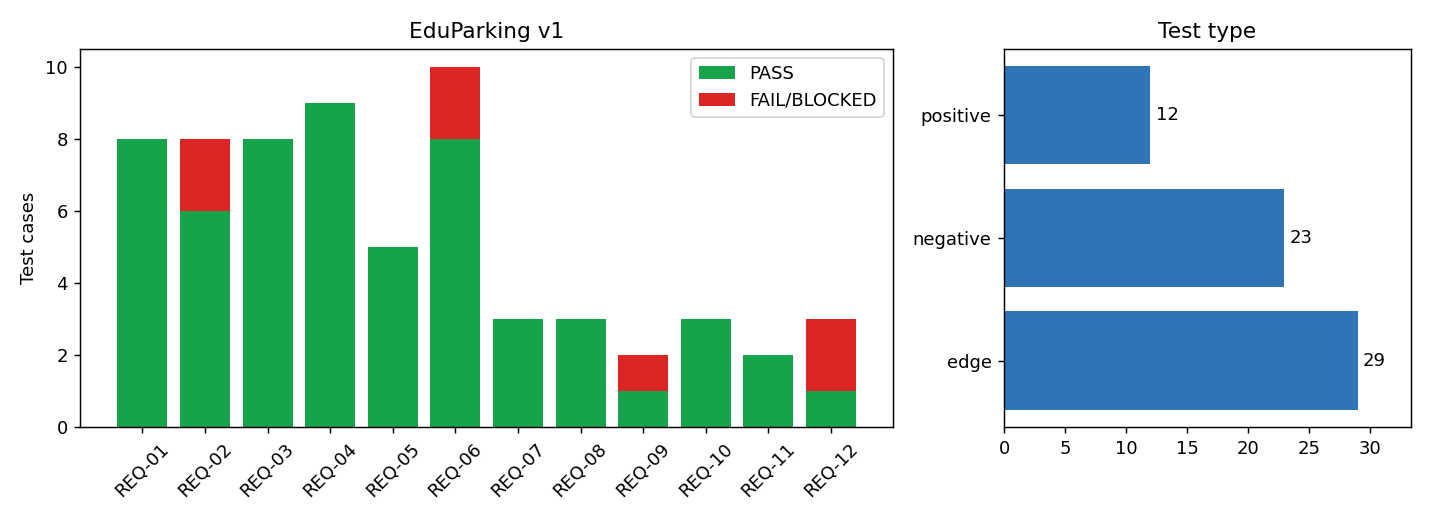

,test_id,requirement,type,test_name,status,time_s,message
12,TC-013,REQ-02,edge,test_edge_duration[case4],FAIL,0.0,assert 2 == 1 + where 2 = parked_hours(datet...
14,TC-015,REQ-02,edge,test_edge_duration[case6],FAIL,0.0,assert 3 == 2 + where 3 = parked_hours(datet...
40,TC-041,REQ-06,edge,test_edge_debt[case2],FAIL,0.0,AssertionError: assert True is False + where...
46,TC-047,REQ-06,negative,test_negative_debt_limit,FAIL,0.0,Failed: DID NOT RAISE <class 'ValueError'>
55,TC-056,REQ-09,edge,test_edge_duplicate_preserves_state,FAIL,0.0,"AssertionError: assert (2, {'59A-123... {}, se..."
62,TC-063,REQ-12,positive,test_positive_ticket[case2],FAIL,0.0,assert 27000 == (7000 + 70000) + where 27000...
63,TC-064,REQ-12,edge,test_edge_ticket_above_cap[case1],FAIL,0.0,assert 207000 == (7000 + 250000) + where 207...


In [9]:
from test_report import build_report
collection = pytest_run("--collect-only", "-q", *TESTS)
assert collection.returncode == 0, collection.stdout
nodes = [s for s in collection.stdout.splitlines() if "::test_" in s]
print(collection.stdout)
v1, summary1, trace1 = build_report("EduParking v1", "parking_app", TESTS, REQUIREMENTS, "reports/v1")
assert list(v1.test_name) == list(data.Test)
display(summary1, trace1, Image("reports/v1/chart.png"))
display(v1[v1.status == "FAIL"])

In [10]:
for row in v1[v1.status == "FAIL"].itertuples():
    node, = [n for n in nodes if n.endswith("::" + row.test_name)]
    run = pytest_run("-q", "--tb=short", node)
    assert run.returncode == 1 and "1 failed" in run.stdout
    print(row.test_id, run.stdout)


TC-013 F                                                                        [100%]
=================================== FAILURES ===================================
_____________________ TestReq02.test_edge_duration[case4] ______________________
test_functions.py:43: in test_edge_duration
    assert parked_hours(START, end) == expected
E   assert 2 == 1
E    +  where 2 = parked_hours(datetime.datetime(2026, 11, 1, 8, 0), datetime.datetime(2026, 11, 1, 9, 0))
=========================== short test summary info ============================
FAILED test_functions.py::TestReq02::test_edge_duration[case4] - assert 2 == 1
1 failed in 0.02s



TC-015 F                                                                        [100%]
=================================== FAILURES ===================================
_____________________ TestReq02.test_edge_duration[case6] ______________________
test_functions.py:43: in test_edge_duration
    assert parked_hours(START, end) == expected
E   assert 3 == 2
E    +  where 3 = parked_hours(datetime.datetime(2026, 11, 1, 8, 0), datetime.datetime(2026, 11, 1, 10, 0))
=========================== short test summary info ============================
FAILED test_functions.py::TestReq02::test_edge_duration[case6] - assert 3 == 2
1 failed in 0.02s



TC-041 F                                                                        [100%]
=================================== FAILURES ===================================
_______________________ TestReq06.test_edge_debt[case2] ________________________
test_parking.py:30: in test_edge_debt
    assert self.lot.can_enter(A) is expected
E   AssertionError: assert True is False
E    +  where True = can_enter('59A-12345')
E    +    where can_enter = <parking_app.ParkingLot object at 0x10ae33b20>.can_enter
E    +      where <parking_app.ParkingLot object at 0x10ae33b20> = <test_parking.TestReq06 object at 0x10ae33cd0>.lot
=========================== short test summary info ============================
FAILED test_parking.py::TestReq06::test_edge_debt[case2] - AssertionError: as...
1 failed in 0.03s



TC-047 F                                                                        [100%]
=================================== FAILURES ===================================
______________________ TestReq06.test_negative_debt_limit ______________________
test_parking.py:56: in test_negative_debt_limit
    self.lot.check_in(A, "CAR", START)
E   Failed: DID NOT RAISE <class 'ValueError'>
=========================== short test summary info ============================
FAILED test_parking.py::TestReq06::test_negative_debt_limit - Failed: DID NOT...
1 failed in 0.03s



TC-056 F                                                                        [100%]
=================================== FAILURES ===================================
________________ TestReq09.test_edge_duplicate_preserves_state _________________
test_parking.py:118: in test_edge_duplicate_preserves_state
    assert snapshot(self.lot) == before
E   AssertionError: assert (2, {'59A-123... {}, set(), 0) == (1, {'59A-123... {}, set(), 0)
E     
E     At index 0 diff: 2 != 1
E     Use -v to get more diff
=========================== short test summary info ============================
FAILED test_parking.py::TestReq09::test_edge_duplicate_preserves_state - Asse...
1 failed in 0.03s



TC-063 F                                                                        [100%]
=================================== FAILURES ===================================
____________________ TestReq12.test_positive_ticket[case2] _____________________
test_parking.py:168: in test_positive_ticket
    assert self.lot.revenue == 7000 + expected
E   assert 27000 == (7000 + 70000)
E    +  where 27000 = <parking_app.ParkingLot object at 0x10813fb80>.revenue
E    +    where <parking_app.ParkingLot object at 0x10813fb80> = <test_parking.TestReq12 object at 0x10813fe20>.lot
=========================== short test summary info ============================
FAILED test_parking.py::TestReq12::test_positive_ticket[case2] - assert 27000...
1 failed in 0.03s



TC-064 F                                                                        [100%]
=================================== FAILURES ===================================
_________________ TestReq12.test_edge_ticket_above_cap[case1] __________________
test_parking.py:178: in test_edge_ticket_above_cap
    assert self.lot.revenue == 7000 + expected
E   assert 207000 == (7000 + 250000)
E    +  where 207000 = <parking_app.ParkingLot object at 0x1066d3100>.revenue
E    +    where <parking_app.ParkingLot object at 0x1066d3100> = <test_parking.TestReq12 object at 0x1066d3370>.lot
=========================== short test summary info ============================
FAILED test_parking.py::TestReq12::test_edge_ticket_above_cap[case1] - assert...
1 failed in 0.03s



## 4. Sửa lỗi đã tái hiện và chạy regression

In [11]:
original = Path("parking_app.py").read_text()
Path("parking_app_v1.py").write_text(original)
fixed = original.replace("from datetime import datetime", "from datetime import timedelta").replace("EduParking v1", "EduParking v2")
fixes = [('minutes = int((time_out - time_in).total_seconds() // 60)\n    return minutes // 60 + 1', 'elapsed = time_out - time_in\n    hours, remainder = divmod(elapsed, timedelta(hours=1))\n    return max(1, hours + bool(remainder))'), ('<= DEBT_LIMIT', '< DEBT_LIMIT'), ('        self.occupied += 1\n        if plate in self.inside:\n            raise ValueError("ALREADY_INSIDE")', '        if plate in self.inside:\n            raise ValueError("ALREADY_INSIDE")\n        self.occupied += 1'), ('        self.revenue += fee\n        if lost_ticket:\n            fee += LOST_TICKET', '        if lost_ticket:\n            fee += LOST_TICKET\n        self.revenue += fee')]
for old, new in fixes:
    assert fixed.count(old) == 1
    fixed = fixed.replace(old, new)
Path("parking_app.py").write_text(fixed)

2522

EduParking v2: executed 64 | PASS 64 | FAIL 0 | BLOCKED 0 | line 100.0% | branch 100.0%


,,executed,pass,fail,blocked,pass_rate_%,req_covered,line_cov_%,branch_cov_%
v1,0,64,57,7,0,89.1,12/12,100.0,100.0
v2,0,64,64,0,0,100.0,12/12,100.0,100.0


,requirement,description,PASS,FAIL,BLOCKED,result
0,REQ-01,"Biển số đúng dạng NNL-NNNNN (2 số, 1 chữ hoa, ...",8,0,0,PASS
1,REQ-02,"Giờ gửi làm tròn LÊN theo giờ, tối thiểu 1 giờ...",8,0,0,PASS
2,REQ-03,"MOTORBIKE: 5.000đ cho 4 giờ đầu, thêm 2.000đ/g...",8,0,0,PASS
3,REQ-04,"CAR: 20.000đ cho 2 giờ đầu, thêm 10.000đ/giờ, ...",9,0,0,PASS
4,REQ-05,Tỉ lệ lấp đầy = số xe / sức chứa × 100; sức ch...,5,0,0,PASS
5,REQ-06,"Được vào khi: biển số hợp lệ, không trong danh...",10,0,0,PASS
6,REQ-07,"Check-in thành công: ghi nhận xe, số xe trong ...",3,0,0,PASS
7,REQ-08,Bãi đầy báo LOT_FULL; dữ liệu không đổi,3,0,0,PASS
8,REQ-09,Xe đang ở trong bãi check-in lại báo ALREADY_I...,2,0,0,PASS
9,REQ-10,"Check-out: trả về phí, số xe giảm 1, xóa xe kh...",3,0,0,PASS


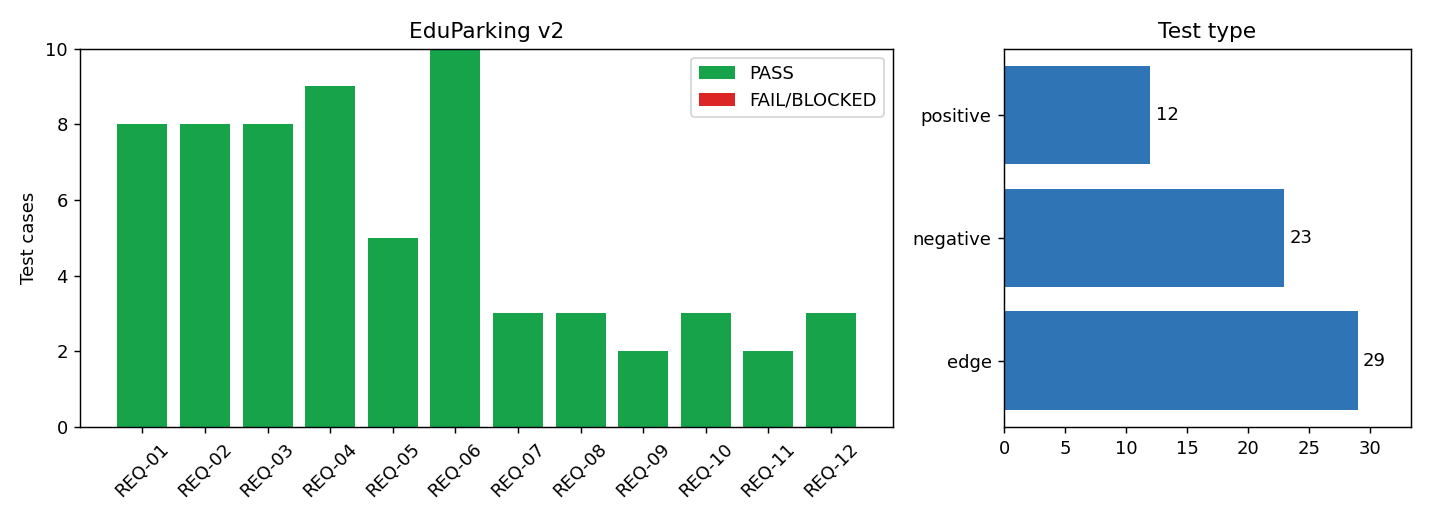

setup_method: 27
        SETUP    F _xunit_setup_method_fixture_TestReq04Entry
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq06
        SETUP    F _xunit_setup_method_fixture_TestReq07
        SETUP    F _xunit_setup_method_fixture_TestReq07
        SETUP    F _xunit_setup_method_fixture_TestReq07
        SETUP    F _xunit_setup_method_fixture_TestReq08
        SETUP    F _xunit_setup_method_fixture_TestReq08
        SETUP    F _xunit_setup_method_fixture_TestReq08
        S

In [12]:
v2, summary2, trace2 = build_report("EduParking v2","parking_app",TESTS,REQUIREMENTS,"reports/v2")
assert list(v1.test_name) == list(v2.test_name) and (v2.status == "PASS").all()
display(pd.concat([summary1, summary2], keys=["v1","v2"]), trace2, Image("reports/v2/chart.png"))
setup = pytest_run("--setup-show", "-q", *TESTS)
lines = [s for s in setup.stdout.splitlines() if "SETUP" in s and "_xunit_setup_method_fixture" in s]
print("setup_method:",len(lines))
print("\n".join(lines))
assert setup.returncode == 0 and lines


## 5. Mutation testing trên sáu bản sao độc lập

In [13]:
mutations = [('M1', 'elapsed = time_out - time_in\n    hours, remainder = divmod(elapsed, timedelta(hours=1))\n    return max(1, hours + bool(remainder))', 'minutes = int((time_out - time_in).total_seconds() // 60)\n    return minutes // 60 + 1'), ('M2', '< DEBT_LIMIT', '<= DEBT_LIMIT'), ('M3', '        if plate in self.inside:\n            raise ValueError("ALREADY_INSIDE")\n        self.occupied += 1', '        self.occupied += 1\n        if plate in self.inside:\n            raise ValueError("ALREADY_INSIDE")'), ('M4', '        if lost_ticket:\n            fee += LOST_TICKET\n        self.revenue += fee', '        self.revenue += fee\n        if lost_ticket:\n            fee += LOST_TICKET'), ('M5', 'return min(fee, cap)', 'return fee'), ('M6', '4, 2_000, 30_000', '4, 3_000, 30_000')]
results = []
for label, old, new in mutations:
    assert fixed.count(old) == 1
    with tempfile.TemporaryDirectory() as folder:
        target = Path(folder)
        (target / "parking_app.py").write_text(fixed.replace(old,new))
        for name in TESTS: shutil.copy(name,target/name)
        run = subprocess.run([sys.executable,"-m","pytest","-q","--tb=no",*TESTS],cwd=target,text=True,capture_output=True)
        failed = [s.split(" - ")[0][7:] for s in run.stdout.splitlines() if s.startswith("FAILED ")]
        outcome = "killed" if run.returncode == 1 and failed else "survived" if run.returncode == 0 else "error"
        results.append([label,outcome,len(failed)," | ".join(failed)])
mutants = pd.DataFrame(results,columns=["mutant","status","failed","tests"])
mutants.to_csv("reports/mutants.csv",index=False)
display(mutants)
assert all(mutants.status == "killed")


,mutant,status,failed,tests
0,M1,killed,2,test_functions.py::TestReq02::test_edge_durati...
1,M2,killed,2,test_parking.py::TestReq06::test_edge_debt[cas...
2,M3,killed,1,test_parking.py::TestReq09::test_edge_duplicat...
3,M4,killed,2,test_parking.py::TestReq12::test_positive_tick...
4,M5,killed,3,test_functions.py::TestReq03::test_edge_fee[ca...
5,M6,killed,2,test_functions.py::TestReq03::test_edge_fee[ca...
